# Advanced Data Preprocessing, Feature Engineering & Model Development
**Pham Quang Minh | Student ID: 104999568**

COS40007 Artificial Intelligence Engineering | Portfolio Assessment 2

Date: 18 October 2026

## Generative AI declaration
OpenAI Codex (GPT-6) assisted with debugging, code polishing and the report. The overall structures,
interpretations and final say are my own.

## Aim
Use concrete ingredients and age to predict one of four strength groups.
Compare decision trees and support vector machines (SVMs).
The dataset is included. Run the notebook cells in order from this folder.

# 1. Prepare the target
Portfolio 1 found no missing values and 25 extra duplicate rows. After removing
these duplicates, 1,005 records remain.

Strength is measured in MPa. Split it into four groups: Lower, Lower-middle,
Upper-middle and Higher. Training-data quartiles make the groups roughly equal
in size. These labels describe this dataset; they are not construction grades.

In [1]:
from pathlib import Path
import json
import hashlib
import platform
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             confusion_matrix, classification_report)

SEED = 42
CLASS_NAMES = ['Lower', 'Lower-middle', 'Upper-middle', 'Higher']
CLASSES = np.arange(4)
ORIGINAL = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer',
            'coarse_aggregate', 'fine_aggregate', 'age']
INGREDIENTS = ORIGINAL[:-1]
for folder in ['figures', 'results']:
    Path(folder).mkdir(exist_ok=True)
pd.set_option('display.width', 110)
pd.set_option('display.max_columns', 14)
pd.set_option('display.precision', 4)
sns.set_theme(style='whitegrid', font_scale=0.9)

def table(data):
    print(data.to_string())

def figure(name):
    plt.savefig(Path('figures') / f'{name}.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close('all')

source = Path('data/Concrete_Data.xls')
raw = pd.read_excel(source, engine='xlrd')
assert raw.shape == (1030, 9)
raw.columns = ORIGINAL + ['strength']
assert raw.notna().all().all() and np.isfinite(raw.to_numpy()).all()
duplicates = int(raw.duplicated().sum())
data = raw.drop_duplicates().copy()
data['age'] = data.age.astype(int)
X = data[ORIGINAL].copy()
y = data.strength.copy()
# Same seven ingredients = same recipe, even if age or measured strength differs.
groups, recipe_values = pd.factorize(pd.MultiIndex.from_frame(X[INGREDIENTS]))
splitter = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_pos, test_pos = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_pos], X.iloc[test_pos]
y_train, y_test = y.iloc[train_pos], y.iloc[test_pos]
g_train, g_test = groups[train_pos], groups[test_pos]
assert set(g_train).isdisjoint(g_test)
assert X_train.index.intersection(X_test.index).empty
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)
print('Source SHA-256:', hashlib.sha256(source.read_bytes()).hexdigest())
print('Raw shape:', raw.shape, '| exact duplicates removed:', duplicates)
print('Clean shape:', data.shape, '| distinct recipes:', len(recipe_values))
print(f'Train: {len(X_train)} rows ({len(X_train)/len(data):.1%}), '
      f'{len(set(g_train))} recipes')
print(f'Test:  {len(X_test)} rows ({len(X_test)/len(data):.1%}), '
      f'{len(set(g_test))} recipes')
print('Shared recipes across train/test:', len(set(g_train) & set(g_test)))
table(raw.isna().sum().to_frame('missing_count'))

Python: 3.12.14 | scikit-learn: 1.9.1
Source SHA-256: 710076c66b9ca3f8050e7942f3dcbdbe04013534daeb0077ffd3079a52d8e0c4
Raw shape: (1030, 9) | exact duplicates removed: 25
Clean shape: (1005, 9) | distinct recipes: 428
Train: 676 rows (67.3%), 299 recipes
Test:  329 rows (32.7%), 129 recipes
Shared recipes across train/test: 0
                  missing_count
cement                        0
slag                          0
fly_ash                       0
water                         0
superplasticizer              0
coarse_aggregate              0
fine_aggregate                0
age                           0
strength                      0


## Training and test data
Keep tests of the same concrete recipe together, even when their ages differ.
This prevents the model seeing the same recipe in training and testing.
A 70/30 split of recipes gives 676 training rows and 329 test rows.

Keep valid zero ingredient amounts and unusual values. No missing-value
replacement is needed.

Training-only boundaries (MPa): [23.23928106064097, 33.45421274036465, 44.34364894]
Rules: <=q25; (q25,q50]; (q50,q75]; >q75
              train_count  test_count  train_percent  test_percent
Lower                 169          77           25.0        23.404
Lower-middle          169          72           25.0        21.884
Upper-middle          169          86           25.0        26.140
Higher                169          94           25.0        28.571


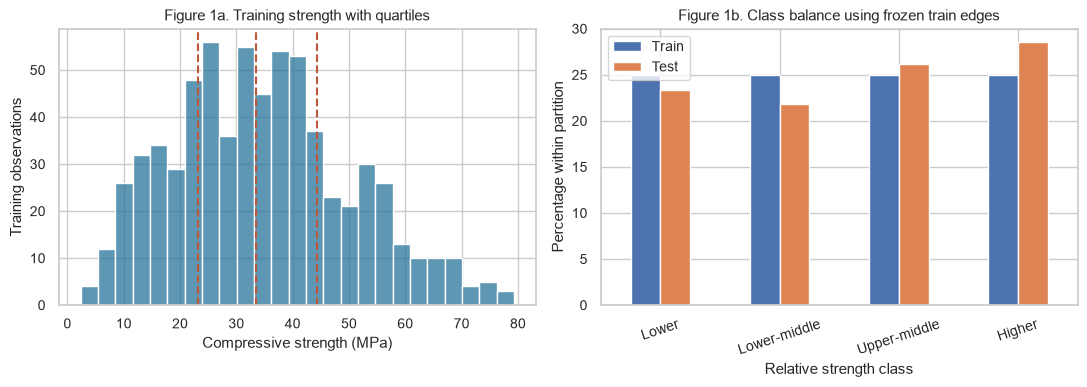

In [2]:
def learn_edges(values):
    edges = np.quantile(np.asarray(values), [0.25, 0.50, 0.75])
    if not np.all(np.diff(edges) > 0):
        raise ValueError('Quartile boundaries are not distinct.')
    return edges

def encode_strength(values, edges):
    # Class 0 <= q25, class 1 (q25,q50], class 2 (q50,q75], class 3 > q75.
    # Infinite outer intervals handle future strengths outside training extrema.
    return np.searchsorted(edges, np.asarray(values), side='left').astype(int)

train_edges = learn_edges(y_train)
y_train_class = encode_strength(y_train, train_edges)
y_test_class = encode_strength(y_test, train_edges)
class_counts = pd.DataFrame({
    'train_count': np.bincount(y_train_class, minlength=4),
    'test_count': np.bincount(y_test_class, minlength=4)}, index=CLASS_NAMES)
class_counts['train_percent'] = 100 * class_counts.train_count / len(y_train)
class_counts['test_percent'] = 100 * class_counts.test_count / len(y_test)
print('Training-only boundaries (MPa):', train_edges.tolist())
print('Rules: <=q25; (q25,q50]; (q50,q75]; >q75')
table(class_counts.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(y_train, bins=25, ax=axes[0], color='#28749b')
for edge in train_edges:
    axes[0].axvline(edge, color='#bd5739', linestyle='--')
axes[0].set(title='Figure 1a. Training strength with quartiles',
            xlabel='Compressive strength (MPa)', ylabel='Training observations')
class_counts[['train_percent', 'test_percent']].plot.bar(ax=axes[1], rot=18)
axes[1].set(title='Figure 1b. Class balance using frozen train edges',
            xlabel='Relative strength class', ylabel='Percentage within partition')
axes[1].legend(['Train', 'Test'])
plt.tight_layout()
figure('01_target_classes')

## How models are checked
Five-fold cross-validation (CV) trains on four parts and checks the fifth,
repeating until each part has been checked. The same recipe stays in one part.
Class boundaries and data transformations are learned only from training data.
When tuning a model, another five-fold check chooses settings inside each
training part. The separate test set is not used to choose settings.

Accuracy is the proportion of correct predictions. Macro F1 balances precision
and recall while giving each class equal weight. Higher is better. Use CV
macro F1 to choose the model. Class MAE shows the average number of bands missed.

# 2. Scale the inputs
Scaling puts measurements on comparable scales:

- Use StandardScaler for water, coarse aggregate and fine aggregate, which
  were relatively symmetric in Portfolio 1.
- Use RobustScaler for cement, slag, fly ash, superplasticizer and age, which
  were more uneven or had extreme values.

All inputs are numeric, so no category encoding is needed. The four target
groups are represented by codes 0-3.

                  skewness  zero_percent    scaler
cement               0.642         0.000    Robust
slag                 0.978        48.373    Robust
fly_ash              0.422        51.479    Robust
water               -0.031         0.000  Standard
superplasticizer     1.022        37.426    Robust
coarse_aggregate    -0.039         0.000  Standard
fine_aggregate      -0.213         0.000  Standard
age                  3.248         0.000    Robust
cement: Broad asymmetric binder distribution; median/IQR scaling
slag: Zero-heavy optional ingredient; broad positive range
fly_ash: Zero-heavy optional ingredient; non-Gaussian mixture
water: Near-symmetric, concentrated distribution; mean/SD scaling
superplasticizer: Many zeros and positive extremes; median/IQR scaling
coarse_aggregate: Near-symmetric distribution; mean/SD scaling
fine_aggregate: Approximately symmetric compared with age/admixtures
age: Strong right tail and long curing ages; median/IQR scaling
                  befo

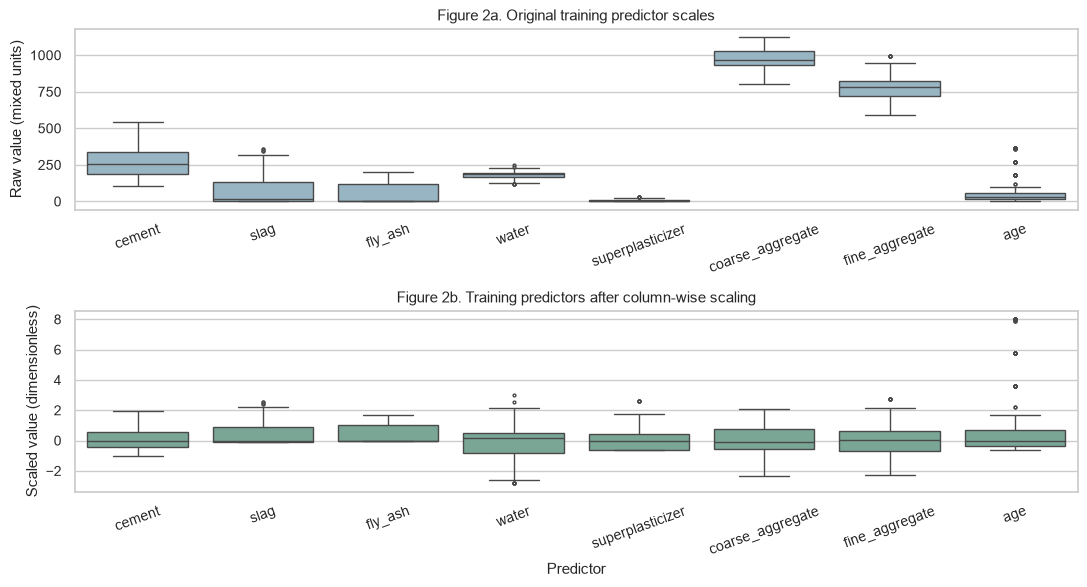

In [3]:
SYMMETRIC = ['water', 'coarse_aggregate', 'fine_aggregate']
ROBUST = [c for c in ORIGINAL if c not in SYMMETRIC]
scale_reasons = {
    'cement': 'Broad asymmetric binder distribution; median/IQR scaling',
    'slag': 'Zero-heavy optional ingredient; broad positive range',
    'fly_ash': 'Zero-heavy optional ingredient; non-Gaussian mixture',
    'water': 'Near-symmetric, concentrated distribution; mean/SD scaling',
    'superplasticizer': 'Many zeros and positive extremes; median/IQR scaling',
    'coarse_aggregate': 'Near-symmetric distribution; mean/SD scaling',
    'fine_aggregate': 'Approximately symmetric compared with age/admixtures',
    'age': 'Strong right tail and long curing ages; median/IQR scaling'}
audit = pd.DataFrame({'skewness': X_train.skew(),
                       'zero_percent': 100 * X_train.eq(0).mean(),
                       'scaler': ['Standard' if c in SYMMETRIC else 'Robust'
                                  for c in ORIGINAL]}, index=ORIGINAL)
table(audit.round(3))
for c in ORIGINAL:
    print(c + ': ' + scale_reasons[c])

def make_scaler(names):
    standard = [c for c in names if c in SYMMETRIC]
    robust = [c for c in names if c not in SYMMETRIC]
    parts = []
    if standard:
        parts.append(('standard', StandardScaler(), standard))
    if robust:
        parts.append(('robust', RobustScaler(), robust))
    return ColumnTransformer(parts, verbose_feature_names_out=False)

demo_scaler = make_scaler(ORIGINAL).fit(X_train)
scaled_names = demo_scaler.get_feature_names_out()
scaled_train = pd.DataFrame(demo_scaler.transform(X_train),
                            columns=scaled_names, index=X_train.index)[ORIGINAL]
comparison = pd.DataFrame({'before_median': X_train.median(),
    'before_IQR': X_train.quantile(.75) - X_train.quantile(.25),
    'after_median': scaled_train.median(),
    'after_IQR': scaled_train.quantile(.75) - scaled_train.quantile(.25)})
table(comparison.round(3))
fig, axes = plt.subplots(2, 1, figsize=(11, 6))
sns.boxplot(data=X_train, ax=axes[0], color='#91b8ca', fliersize=2)
sns.boxplot(data=scaled_train, ax=axes[1], color='#72ad97', fliersize=2)
axes[0].set(title='Figure 2a. Original training predictor scales',
            xlabel='', ylabel='Raw value (mixed units)')
axes[1].set(title='Figure 2b. Training predictors after column-wise scaling',
            xlabel='Predictor', ylabel='Scaled value (dimensionless)')
for ax in axes:
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
figure('02_scaling_comparison')

Scaling helps SVMs compare inputs fairly, so large ingredient quantities do not
overwhelm smaller measurements. It usually matters less for decision trees.
Before PCA, inputs are also standardised to equal variance.

# 3. Create useful features
Portfolio 1 suggested looking at ingredient ratios and the effect of age.
Add five features:

- `binder_total = cement + slag + fly_ash`: total binder amount (kg/m^3).
- `water_binder_ratio = water / binder_total`: water relative to binder.
- `log_age = log(1 + age)`: reduces the effect of very large ages.
- `scm_fraction = (slag + fly_ash) / binder_total`: share of replacement binder.
- `maturity_ratio = log_age / water_binder_ratio`: an experimental age-water
  combination, not a standard engineering maturity measure.

The checks below confirm the values are valid and show their relationships
with training strength. No feature uses the measured target strength.

                    Pearson_r  Spearman_rho
binder_total           0.5820        0.5765
water_binder_ratio    -0.5987       -0.5837
log_age                0.5546        0.5915
scm_fraction          -0.0944       -0.1146
maturity_ratio         0.8620        0.8647
Engineered feature validity checks passed.
Strongest pairwise dependencies among expanded inputs:
      feature_1           feature_2  Pearson_r
0  binder_total  water_binder_ratio    -0.8762


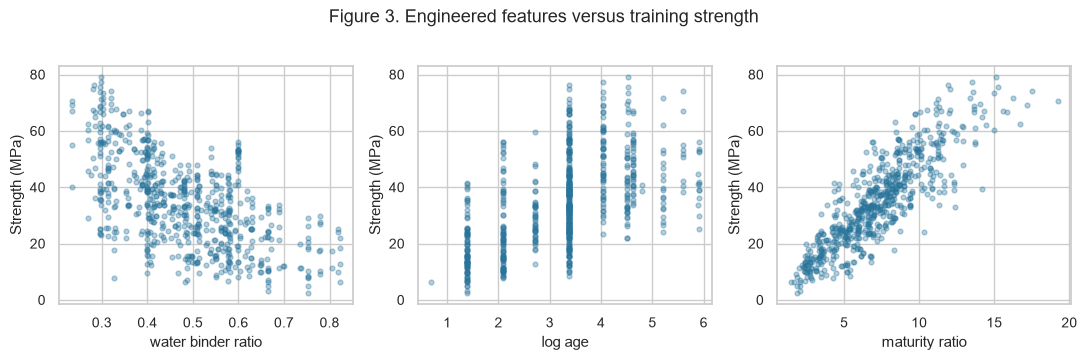

In [4]:
ENGINEERED = ['binder_total', 'water_binder_ratio', 'log_age',
              'scm_fraction', 'maturity_ratio']
ALL_FEATURES = ORIGINAL + ENGINEERED
DOMAIN = ['binder_total', 'water_binder_ratio', 'log_age',
          'scm_fraction', 'superplasticizer']

def engineer(frame):
    out = frame[ORIGINAL].copy()
    out['binder_total'] = out.cement + out.slag + out.fly_ash
    if (out.binder_total <= 0).any() or (out.water <= 0).any():
        raise ValueError('Positive binder and water are required for ratios.')
    out['water_binder_ratio'] = out.water / out.binder_total
    out['log_age'] = np.log1p(out.age)
    out['scm_fraction'] = (out.slag + out.fly_ash) / out.binder_total
    out['maturity_ratio'] = out.log_age / out.water_binder_ratio
    assert np.isfinite(out.to_numpy()).all()
    assert out.scm_fraction.between(0, 1).all()
    return out

engineered_train = engineer(X_train)
association = pd.DataFrame({
    'Pearson_r': engineered_train.corrwith(y_train),
    'Spearman_rho': engineered_train.corrwith(y_train, method='spearman')})
table(association.loc[ENGINEERED].round(4))
print('Engineered feature validity checks passed.')
print('Strongest pairwise dependencies among expanded inputs:')
corr = engineered_train.corr()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(ALL_FEATURES)
         for b in ALL_FEATURES[i+1:] if abs(corr.loc[a, b]) >= .80]
table(pd.DataFrame(pairs, columns=['feature_1', 'feature_2', 'Pearson_r']).round(4))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for c, ax in zip(['water_binder_ratio', 'log_age', 'maturity_ratio'], axes):
    ax.scatter(engineered_train[c], y_train, alpha=.35, s=12, color='#28749b')
    ax.set(xlabel=c.replace('_', ' '), ylabel='Strength (MPa)')
fig.suptitle('Figure 3. Engineered features versus training strength', y=1.02)
plt.tight_layout()
figure('03_engineered_relationships')

Some new features overlap with the original inputs. Compare model results to
see whether the extra information helps.

# 4. Compare five decision trees
Test five input sets:

- Original: all eight original inputs.
- Top 5: five inputs most correlated with training strength.
- Expanded: eight original inputs plus five new features.
- PCA 5: five combined inputs produced by PCA.
- Domain: five inputs chosen for their engineering meaning.

Every tree uses maximum depth 6 and at least 5 records per leaf. Using the
same settings makes the feature-set comparison easier to interpret.

In [5]:
class FeatureBuilder(TransformerMixin, BaseEstimator):
    def __init__(self, feature_set='original'):
        self.feature_set = feature_set

    def fit(self, X, y=None):
        if self.feature_set == 'top5':
            scores = X[ORIGINAL].corrwith(pd.Series(np.asarray(y), index=X.index))
            self.columns_ = list(scores.abs().sort_values(ascending=False).head(5).index)
        elif self.feature_set == 'expanded':
            self.columns_ = ALL_FEATURES.copy()
        elif self.feature_set == 'domain':
            self.columns_ = DOMAIN.copy()
        else:
            self.columns_ = ORIGINAL.copy()
        self.feature_names_in_ = np.asarray(ORIGINAL, dtype=object)
        return self

    def transform(self, X):
        return engineer(X)[self.columns_]

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns_, dtype=object)

class AdaptiveScaler(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        self.scaler_ = make_scaler(list(X.columns)).fit(X)
        return self

    def transform(self, X):
        return self.scaler_.transform(X)

    def get_feature_names_out(self, input_features=None):
        return self.scaler_.get_feature_names_out()

def preprocessing(feature_set='expanded', reduction=None, unscaled=False):
    steps = [('build', FeatureBuilder(feature_set))]
    if not unscaled:
        steps.append(('scale', AdaptiveScaler()))
    if reduction == 'pca5':
        steps += [('unit_variance', StandardScaler()), ('pca', PCA(n_components=5))]
    elif reduction == 'pca':
        steps += [('unit_variance', StandardScaler()),
                  ('pca', PCA(n_components=.90, svd_solver='full'))]
    elif reduction == 'kbest':
        steps.append(('kbest', SelectKBest(score_func=f_classif, k=8)))
    return Pipeline(steps)

class RelativeStrengthClassifier(ClassifierMixin, BaseEstimator):
    # y remains continuous at the API boundary so binning can be learned per fit.
    def __init__(self, features=None, classifier=None, selection_uses_classes=False):
        self.features = features
        self.classifier = classifier
        self.selection_uses_classes = selection_uses_classes

    def fit(self, X, y):
        self.edges_ = learn_edges(y)
        labels = self.encode_target(y)
        self.classes_ = CLASSES.copy()
        selection_y = labels if self.selection_uses_classes else np.asarray(y)
        self.features_ = clone(self.features)
        transformed = self.features_.fit_transform(X, selection_y)
        self.classifier_ = clone(self.classifier).fit(transformed, labels)
        self.n_features_in_ = X.shape[1]
        return self

    def encode_target(self, y):
        return encode_strength(y, self.edges_)

    def predict(self, X):
        return self.classifier_.predict(self.features_.transform(X))

    def score(self, X, y):
        return accuracy_score(self.encode_target(y), self.predict(X))

def metrics(estimator, X, raw_y):
    actual, predicted = estimator.encode_target(raw_y), estimator.predict(X)
    return {'accuracy': accuracy_score(actual, predicted),
            'macro_f1': f1_score(actual, predicted, labels=CLASSES,
                                  average='macro', zero_division=0),
            'balanced_accuracy': balanced_accuracy_score(actual, predicted),
            'class_MAE': float(np.abs(actual - predicted).mean())}

def search_scoring(estimator, X, raw_y):
    # A callable scorer bins validation strengths using fitted training edges.
    result = metrics(estimator, X, raw_y)
    return {k: v for k, v in result.items() if k != 'class_MAE'}

outer_cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
FOLDS = list(outer_cv.split(X_train, y_train, g_train))
for fit_idx, valid_idx in FOLDS:
    assert set(g_train[fit_idx]).isdisjoint(g_train[valid_idx])
print('Five recipe-group CV folds verified; all target preparation is inside fit().')

Five recipe-group CV folds verified; all target preparation is inside fit().


In [6]:
def compare_on_training(name, estimator, parameter_grid=None):
    start = time.perf_counter()
    rows = []
    for fold, (fit_idx, valid_idx) in enumerate(FOLDS, start=1):
        candidate = clone(estimator)
        if parameter_grid is not None:
            candidate = GridSearchCV(candidate, parameter_grid,
                scoring=search_scoring, refit='macro_f1',
                cv=GroupKFold(n_splits=5, shuffle=True, random_state=SEED + fold),
                n_jobs=1, error_score='raise')
            candidate.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx],
                          groups=g_train[fit_idx])
            fitted = candidate.best_estimator_
        else:
            fitted = candidate.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        score = metrics(fitted, X_train.iloc[valid_idx], y_train.iloc[valid_idx])
        score.update(fold=fold, model=name,
                     q25=fitted.edges_[0], q50=fitted.edges_[1], q75=fitted.edges_[2])
        rows.append(score)
    if parameter_grid is None:
        final = clone(estimator).fit(X_train, y_train)
        search = None
    else:
        search = GridSearchCV(clone(estimator), parameter_grid,
            scoring=search_scoring, refit='macro_f1',
            cv=GroupKFold(n_splits=5, shuffle=True, random_state=SEED + 100),
            n_jobs=1, error_score='raise')
        search.fit(X_train, y_train, groups=g_train)
        final = search.best_estimator_
    folds = pd.DataFrame(rows)
    summary = {'model': name, 'features': final.features_.transform(X_train).shape[1],
               'train_accuracy': metrics(final, X_train, y_train)['accuracy'],
               'CV_accuracy': folds.accuracy.mean(),
               'CV_accuracy_SD': folds.accuracy.std(ddof=1),
               'CV_macro_F1': folds.macro_f1.mean(),
               'CV_F1_SD': folds.macro_f1.std(ddof=1),
               'CV_class_MAE': folds.class_MAE.mean(),
               'seconds': time.perf_counter() - start}
    print(f'{name}: 5-fold macro F1={summary["CV_macro_F1"]:.4f} '
          f'+/- {summary["CV_F1_SD"]:.4f}', flush=True)
    return summary, final, folds, search

TREE_SETS = {'DT Original': ('original', None),
             'DT Top 5': ('top5', None),
             'DT Expanded': ('expanded', None),
             'DT PCA 5': ('original', 'pca5'),
             'DT Domain': ('domain', None)}
tree_rows, tree_models, fold_records = [], {}, []
for name, (feature_set, reduction) in TREE_SETS.items():
    estimator = RelativeStrengthClassifier(
        features=preprocessing(feature_set, reduction),
        classifier=DecisionTreeClassifier(max_depth=6, min_samples_leaf=5,
                                            random_state=SEED))
    summary, fitted, folds, _ = compare_on_training(name, estimator)
    tree_rows.append(summary)
    tree_models[name] = fitted
    fold_records.append(folds)
tree_cv = pd.DataFrame(tree_rows).set_index('model')
best_tree_name = tree_cv.CV_macro_F1.idxmax()
best_tree = tree_models[best_tree_name]
print('Best tree by training CV macro F1:', best_tree_name)
print('Full-training top-correlated features:',
      tree_models['DT Top 5'].features_.named_steps['build'].columns_)

DT Original: 5-fold macro F1=0.5700 +/- 0.0174


DT Top 5: 5-fold macro F1=0.5712 +/- 0.0434


DT Expanded: 5-fold macro F1=0.6488 +/- 0.0685


DT PCA 5: 5-fold macro F1=0.4321 +/- 0.0127

DT Domain: 5-fold macro F1=0.6616 +/- 0.0478


Best tree by training CV macro F1: DT Domain
Full-training top-correlated features: ['cement', 'age', 'superplasticizer', 'water', 'fine_aggregate']


# 5. Decision-tree results
Compare all five trees using the same split and CV groups. Select the best
tree by CV macro F1, then check its test performance.

             features  train_accuracy  CV_accuracy  CV_macro_F1  CV_F1_SD  test_accuracy  test_macro_f1
model                                                                                                  
DT Original         8          0.7115       0.5702       0.5700    0.0174         0.6839         0.6808
DT Top 5            5          0.7056       0.5662       0.5712    0.0434         0.6565         0.6494
DT Expanded        13          0.8047       0.6495       0.6488    0.0685         0.7477         0.7443
DT PCA 5            5          0.6716       0.4453       0.4321    0.0127         0.5106         0.5017
DT Domain           5          0.8047       0.6615       0.6616    0.0478         0.7325         0.7301


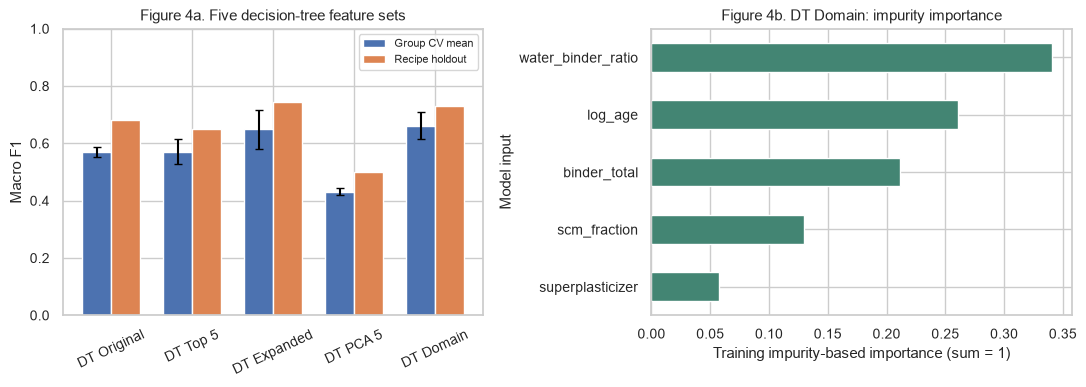

Best-tree input importances:
                    importance
water_binder_ratio      0.3406
log_age                 0.2609
binder_total            0.2115
scm_fraction            0.1299
superplasticizer        0.0571


In [7]:
tree_holdout = pd.DataFrame({name: metrics(model, X_test, y_test)
                            for name, model in tree_models.items()}).T
first_table = tree_cv.join(tree_holdout.add_prefix('test_'))
first_columns = ['features', 'train_accuracy', 'CV_accuracy', 'CV_macro_F1',
                 'CV_F1_SD', 'test_accuracy', 'test_macro_f1']
table(first_table[first_columns].round(4))
first_table.to_csv('results/first_decision_tree_comparison.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
positions = np.arange(len(tree_cv))
axes[0].bar(positions - .18, tree_cv.CV_macro_F1, .36, label='Group CV mean')
axes[0].bar(positions + .18, tree_holdout.macro_f1, .36, label='Recipe holdout')
axes[0].errorbar(positions - .18, tree_cv.CV_macro_F1,
                 yerr=tree_cv.CV_F1_SD, fmt='none', color='black', capsize=3)
axes[0].set(xticks=positions, xticklabels=tree_cv.index, ylim=(0, 1),
            title='Figure 4a. Five decision-tree feature sets', ylabel='Macro F1')
axes[0].tick_params(axis='x', rotation=25)
axes[0].legend(fontsize=8)
importance = pd.Series(best_tree.classifier_.feature_importances_,
    index=best_tree.features_.get_feature_names_out()).sort_values()
importance.plot.barh(ax=axes[1], color='#438573')
axes[1].set(title=f'Figure 4b. {best_tree_name}: impurity importance',
            xlabel='Training impurity-based importance (sum = 1)', ylabel='Model input')
plt.tight_layout()
figure('04_tree_comparison_importance')
print('Best-tree input importances:')
table(importance.sort_values(ascending=False).to_frame('importance').round(4))

**DT Domain** has the best tree CV macro F1 (0.662).
Water-to-binder ratio and log age are its most important inputs. This suggests
a small set of meaningful engineering features can work well.
The importance chart describes this fitted tree, not cause and effect.

# 6. Try an SVM
An SVM learns boundaries between the four strength groups. Start with all
13 scaled inputs, an RBF kernel, C=1 and gamma='scale'. Also check an unscaled
SVM to see how much scaling helps.

In [8]:
svm_base = RelativeStrengthClassifier(features=preprocessing('expanded'),
    classifier=SVC(kernel='rbf', C=1, gamma='scale', cache_size=512))
baseline_summary, baseline_svm, baseline_folds, _ = compare_on_training(
    'SVM Baseline', svm_base)
svm_rows = [baseline_summary]
svm_models = {'SVM Baseline': baseline_svm}
fold_records.append(baseline_folds)
unscaled = RelativeStrengthClassifier(
    features=preprocessing('expanded', unscaled=True),
    classifier=SVC(kernel='rbf', C=1, gamma='scale', cache_size=512))
unscaled_summary, _, _, _ = compare_on_training('SVM Unscaled control', unscaled)
table(pd.DataFrame([unscaled_summary, baseline_summary])[
    ['model', 'CV_accuracy', 'CV_macro_F1', 'CV_F1_SD']].set_index('model').round(4))
print('Baseline holdout metrics (fixed model; no tuning from holdout):')
table(pd.Series(metrics(baseline_svm, X_test, y_test)).to_frame('value').round(4))

SVM Baseline: 5-fold macro F1=0.7147 +/- 0.0341


SVM Unscaled control: 5-fold macro F1=0.4104 +/- 0.0250

                      CV_accuracy  CV_macro_F1  CV_F1_SD
model                                                   
SVM Unscaled control       0.4526       0.4104    0.0250
SVM Baseline               0.7105       0.7147    0.0341
Baseline holdout metrics (fixed model; no tuning from holdout):
                    value
accuracy           0.7872
macro_f1           0.7832
balanced_accuracy  0.7810
class_MAE          0.2249


# 7. Tune the SVM
GridSearchCV tries nine combinations of C and gamma. C controls the penalty
for training errors; gamma controls how locally each point affects the
boundary. Choose settings using training CV, not the test set.

In [9]:
svm_grid = {'classifier__C': [1, 10, 100],
            'classifier__gamma': ['scale', .03, .1]}
tuned_summary, tuned_svm, tuned_folds, tuned_search = compare_on_training(
    'SVM Tuned', svm_base, svm_grid)
svm_rows.append(tuned_summary)
svm_models['SVM Tuned'] = tuned_svm
fold_records.append(tuned_folds)
print('Full-training search best parameters:', tuned_search.best_params_)
print('Inner selection macro F1:', round(tuned_search.best_score_, 4))
print('Nested outer macro F1:', round(tuned_summary['CV_macro_F1'], 4))
tuning_results = pd.DataFrame(tuned_search.cv_results_)
table(tuning_results[['param_classifier__C', 'param_classifier__gamma',
    'mean_test_macro_f1', 'std_test_macro_f1', 'rank_test_macro_f1']]
    .sort_values('rank_test_macro_f1').round(4))
tuning_results.to_csv('results/svm_tuning_grid.csv', index=False)

SVM Tuned: 5-fold macro F1=0.7468 +/- 0.0365


Full-training search best parameters: {'classifier__C': 100, 'classifier__gamma': 0.1}
Inner selection macro F1: 0.7393
Nested outer macro F1: 0.7468
   param_classifier__C param_classifier__gamma  mean_test_macro_f1  std_test_macro_f1  rank_test_macro_f1
8                  100                     0.1              0.7393             0.0284                   1
6                  100                   scale              0.7391             0.0286                   2
7                  100                    0.03              0.7344             0.0297                   3
4                   10                    0.03              0.7334             0.0352                   4
5                   10                     0.1              0.7297             0.0350                   5
3                   10                   scale              0.7270             0.0362                   6
0                    1                   scale              0.7238             0.0289                   7
2 

# 8. Select fewer features
K-Best ranks features by how well they separate the classes. Try keeping
5, 8 or 11 inputs, and let training CV choose the setting.
The final model keeps **11 of 13 features**. Their names appear below.

In [10]:
kbest_base = RelativeStrengthClassifier(
    features=preprocessing('expanded', 'kbest'),
    classifier=SVC(kernel='rbf', cache_size=512), selection_uses_classes=True)
kbest_grid = {'features__kbest__k': [5, 8, 11],
              'classifier__C': [1, 10], 'classifier__gamma': ['scale', .1]}
k_summary, k_svm, k_folds, k_search = compare_on_training(
    'SVM K-Best', kbest_base, kbest_grid)
svm_rows.append(k_summary)
svm_models['SVM K-Best'] = k_svm
fold_records.append(k_folds)
print('Best K-Best parameters:', k_search.best_params_)
print('Selected features:', list(k_svm.features_.get_feature_names_out()))
pre_select_names = k_svm.features_[:-1].get_feature_names_out()
f_scores = pd.Series(k_svm.features_.named_steps['kbest'].scores_,
                     index=pre_select_names).sort_values(ascending=False)
table(f_scores.to_frame('training_ANOVA_F').round(3))

SVM K-Best: 5-fold macro F1=0.7246 +/- 0.0261


Best K-Best parameters: {'classifier__C': 10, 'classifier__gamma': 0.1, 'features__kbest__k': 11}
Selected features: ['water', 'coarse_aggregate', 'fine_aggregate', 'cement', 'superplasticizer', 'age', 'binder_total', 'water_binder_ratio', 'log_age', 'scm_fraction', 'maturity_ratio']
                    training_ANOVA_F
maturity_ratio               398.135
log_age                      107.249
water_binder_ratio           103.732
binder_total                  90.767
cement                        48.556
age                           31.575
superplasticizer              25.461
water                         17.182
fine_aggregate                11.532
coarse_aggregate               6.521
scm_fraction                   1.466
slag                           1.328
fly_ash                        0.906


# 9. Reduce inputs with PCA
PCA combines related inputs into fewer components. Try retaining 80%, 90%
or 95% of input variance and choose using training CV.
The selected model uses **7 components**, keeping about
**97%** of training variance. Keeping variance does not guarantee
better predictions.

SVM PCA: 5-fold macro F1=0.7405 +/- 0.0347


Best PCA parameters: {'classifier__C': 10, 'classifier__gamma': 0.1, 'features__pca__n_components': 0.95}
Selected components: 7
Retained variance: 0.9699
    component  variance_ratio  cumulative
0           1          0.2621      0.2621
1           2          0.2094      0.4714
2           3          0.1768      0.6482
3           4          0.1472      0.7954
4           5          0.0837      0.8791
5           6          0.0689      0.9480
6           7          0.0220      0.9699
7           8          0.0199      0.9899
8           9          0.0041      0.9939
9          10          0.0027      0.9966
10         11          0.0019      0.9985
11         12          0.0015      1.0000
12         13          0.0000      1.0000


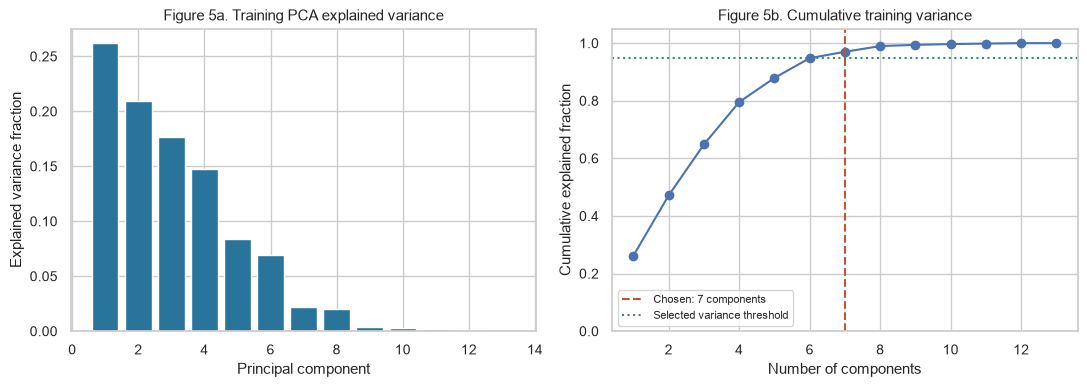

In [11]:
pca_base = RelativeStrengthClassifier(features=preprocessing('expanded', 'pca'),
    classifier=SVC(kernel='rbf', cache_size=512))
pca_grid = {'features__pca__n_components': [.80, .90, .95],
            'classifier__C': [1, 10], 'classifier__gamma': ['scale', .1]}
p_summary, p_svm, p_folds, p_search = compare_on_training(
    'SVM PCA', pca_base, pca_grid)
svm_rows.append(p_summary)
svm_models['SVM PCA'] = p_svm
fold_records.append(p_folds)
print('Best PCA parameters:', p_search.best_params_)
chosen_pca = p_svm.features_.named_steps['pca']
print('Selected components:', chosen_pca.n_components_)
print('Retained variance:', round(chosen_pca.explained_variance_ratio_.sum(), 4))
before_pca = p_svm.features_[:-1].transform(X_train)
pca_diagnostic = PCA().fit(before_pca)
variance = pd.DataFrame({'component': np.arange(1, before_pca.shape[1] + 1),
    'variance_ratio': pca_diagnostic.explained_variance_ratio_,
    'cumulative': np.cumsum(pca_diagnostic.explained_variance_ratio_)})
table(variance.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(variance.component, variance.variance_ratio, color='#28749b')
axes[0].set(title='Figure 5a. Training PCA explained variance',
            xlabel='Principal component', ylabel='Explained variance fraction')
axes[1].plot(variance.component, variance.cumulative, marker='o')
axes[1].axvline(chosen_pca.n_components_, color='#bd5739', linestyle='--',
                label=f'Chosen: {chosen_pca.n_components_} components')
axes[1].axhline(float(p_search.best_params_['features__pca__n_components']),
                color='#438573', linestyle=':', label='Selected variance threshold')
axes[1].set(title='Figure 5b. Cumulative training variance',
            xlabel='Number of components', ylabel='Cumulative explained fraction',
            ylim=(0, 1.05))
axes[1].legend(fontsize=8)
plt.tight_layout()
figure('05_pca_variance')

# 10. Final comparison
Compare the baseline, tuned, K-Best and PCA SVMs. Choose using CV macro F1;
use the separate test results as a final check. The baseline is fixed, while
CV for the other models includes their tuning steps.

In [12]:
svm_cv = pd.DataFrame(svm_rows).set_index('model')
selected_svm_name = svm_cv.CV_macro_F1.idxmax()
selected_svm = svm_models[selected_svm_name]
svm_holdout = pd.DataFrame({name: metrics(model, X_test, y_test)
                           for name, model in svm_models.items()}).T
final_table = svm_cv.join(svm_holdout.add_prefix('test_'))
final_columns = ['features', 'CV_accuracy', 'CV_accuracy_SD', 'CV_macro_F1',
                 'CV_F1_SD', 'test_accuracy', 'test_macro_f1', 'test_class_MAE']
table(final_table[final_columns].round(4))
print('SVM selected using training CV:', selected_svm_name)
print('Tuned-minus-baseline outer CV F1:',
      round(svm_cv.loc['SVM Tuned', 'CV_macro_F1'] - baseline_summary['CV_macro_F1'], 4))
print('Tuned-minus-baseline holdout F1:',
      round(svm_holdout.loc['SVM Tuned', 'macro_f1'] -
            svm_holdout.loc['SVM Baseline', 'macro_f1'], 4))
print('Scaling-control CV F1 difference:',
      round(baseline_summary['CV_macro_F1'] - unscaled_summary['CV_macro_F1'], 4))
majority_class = int(np.argmax(np.bincount(y_train_class, minlength=4)))
dummy_pred = np.repeat(majority_class, len(y_test_class))
print('Training-majority dummy holdout accuracy:',
      round(accuracy_score(y_test_class, dummy_pred), 4))
print('Selected SVM holdout class report:')
print(classification_report(y_test_class, selected_svm.predict(X_test),
    labels=CLASSES, target_names=CLASS_NAMES, digits=3, zero_division=0))
final_table.to_csv('results/final_svm_comparison.csv')
all_folds = pd.concat(fold_records, ignore_index=True)
all_folds.to_csv('results/cross_validation_folds.csv', index=False)

              features  CV_accuracy  CV_accuracy_SD  CV_macro_F1  CV_F1_SD  test_accuracy  test_macro_f1  test_class_MAE
model                                                                                                                   
SVM Baseline        13       0.7105          0.0345       0.7147    0.0341         0.7872         0.7832          0.2249
SVM Tuned           13       0.7448          0.0367       0.7468    0.0365         0.8085         0.8063          0.2036
SVM K-Best          11       0.7212          0.0302       0.7246    0.0261         0.8024         0.8032          0.2097
SVM PCA              7       0.7387          0.0360       0.7405    0.0347         0.8207         0.8171          0.1945
SVM selected using training CV: SVM Tuned
Tuned-minus-baseline outer CV F1: 0.0321
Tuned-minus-baseline holdout F1: 0.0232
Scaling-control CV F1 difference: 0.3043
Training-majority dummy holdout accuracy: 0.234
Selected SVM holdout class report:
              precision    

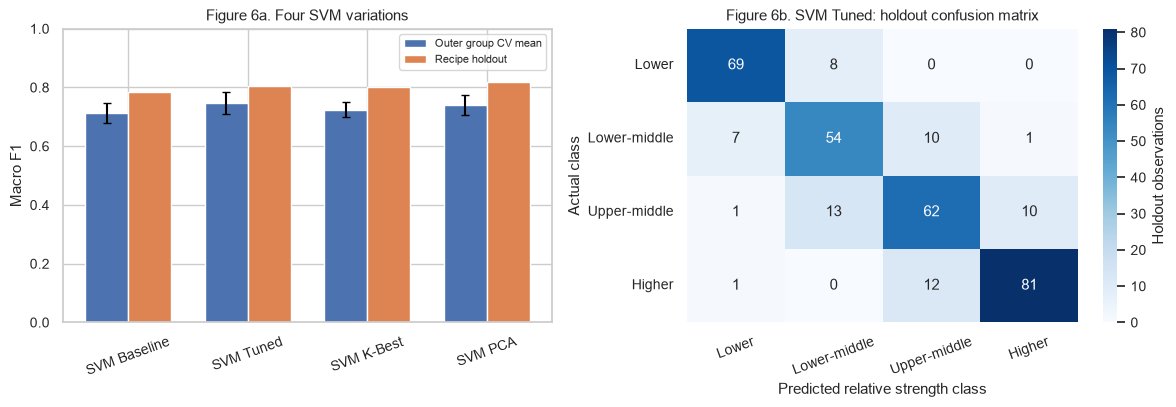

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
positions = np.arange(len(svm_cv))
axes[0].bar(positions - .18, svm_cv.CV_macro_F1, .36, label='Outer group CV mean')
axes[0].bar(positions + .18, svm_holdout.macro_f1, .36, label='Recipe holdout')
axes[0].errorbar(positions - .18, svm_cv.CV_macro_F1, yerr=svm_cv.CV_F1_SD,
                 fmt='none', capsize=3, color='black')
axes[0].set(xticks=positions, xticklabels=svm_cv.index, ylim=(0, 1),
            title='Figure 6a. Four SVM variations', ylabel='Macro F1')
axes[0].tick_params(axis='x', rotation=20)
axes[0].legend(fontsize=8)
matrix = confusion_matrix(y_test_class, selected_svm.predict(X_test), labels=CLASSES)
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar_kws={'label': 'Holdout observations'})
axes[1].set(title=f'Figure 6b. {selected_svm_name}: holdout confusion matrix',
            xlabel='Predicted relative strength class', ylabel='Actual class')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
figure('06_final_svm_comparison')

In [14]:
# Save an audit trail; no executable model pickle is needed to reproduce this work.
split_audit = data.copy()
split_audit['recipe_group'] = groups
split_audit['partition'] = 'test'
split_audit.loc[X_train.index, 'partition'] = 'train'
split_audit['strength_class_code'] = encode_strength(data.strength, train_edges)
split_audit['strength_class'] = np.asarray(CLASS_NAMES)[split_audit.strength_class_code]
split_audit.to_csv('data/partitioned_concrete.csv', index_label='source_row')
predictions = pd.DataFrame({'actual_strength_MPa': y_test,
    'actual_class_code': y_test_class}, index=X_test.index)
for name, model in {**tree_models, **svm_models}.items():
    assert np.allclose(model.edges_, train_edges)
    predictions[name] = model.predict(X_test)
predictions.to_csv('results/holdout_predictions.csv', index_label='source_row')
pd.DataFrame({'feature': list(scale_reasons),
              'reason': list(scale_reasons.values())}).to_csv(
                  'results/scaling_rationale.csv', index=False)
metadata = {
    'author': 'Pham Quang Minh', 'date': '2026-10-18', 'seed': SEED,
    'source_doi': '10.24432/C5PK67',
    'source_sha256': hashlib.sha256(source.read_bytes()).hexdigest(),
    'raw_rows': len(raw), 'clean_rows': len(data), 'duplicates_removed': duplicates,
    'train_rows': len(X_train), 'test_rows': len(X_test),
    'train_recipes': len(set(g_train)), 'test_recipes': len(set(g_test)),
    'class_names': CLASS_NAMES, 'training_edges_MPa': train_edges.tolist(),
    'class_rule': '(-inf,q25], (q25,q50], (q50,q75], (q75,inf)',
    'target_CV': 'Quartiles refitted within each fit, including inner and outer folds',
    'best_tree_by_CV': best_tree_name, 'selected_SVM_by_CV': selected_svm_name,
    'selected_K': int(k_search.best_params_['features__kbest__k']),
    'K_features': list(k_svm.features_.get_feature_names_out()),
    'PCA_components': int(chosen_pca.n_components_),
    'PCA_variance': float(chosen_pca.explained_variance_ratio_.sum()),
    'tuned_parameters': tuned_search.best_params_,
    'K_parameters': k_search.best_params_, 'PCA_parameters': p_search.best_params_,
    'versions': {'python': platform.python_version(), 'sklearn': sklearn.__version__,
                 'numpy': np.__version__, 'pandas': pd.__version__}}
Path('results/reproducibility.json').write_text(json.dumps(metadata, indent=2))
summary = {
    'best_tree': best_tree_name,
    'tree_CV_F1': float(tree_cv.loc[best_tree_name, 'CV_macro_F1']),
    'tree_test_F1': float(tree_holdout.loc[best_tree_name, 'macro_f1']),
    'best_svm': selected_svm_name,
    'svm_CV_F1': float(svm_cv.loc[selected_svm_name, 'CV_macro_F1']),
    'svm_test_F1': float(svm_holdout.loc[selected_svm_name, 'macro_f1']),
    'svm_test_accuracy': float(svm_holdout.loc[selected_svm_name, 'accuracy']),
    'svm_test_class_MAE': float(svm_holdout.loc[selected_svm_name, 'class_MAE']),
    'tuning_CV_delta': float(tuned_summary['CV_macro_F1'] -
                             baseline_summary['CV_macro_F1']),
    'tuning_test_delta': float(svm_holdout.loc['SVM Tuned', 'macro_f1'] -
                               svm_holdout.loc['SVM Baseline', 'macro_f1']),
    'scale_CV_delta': float(baseline_summary['CV_macro_F1'] -
                            unscaled_summary['CV_macro_F1']),
    'expanded_tree_delta': float(tree_cv.loc['DT Expanded', 'CV_macro_F1'] -
                                  tree_cv.loc['DT Original', 'CV_macro_F1']),
    'dummy_accuracy': float(accuracy_score(y_test_class, dummy_pred))}
Path('results/summary.json').write_text(json.dumps(summary, indent=2))
assert len(tree_models) == 5 and len(svm_models) == 4
assert len(all_folds) == 45
assert set(g_train).isdisjoint(g_test)
assert len(predictions) == len(X_test) and predictions.notna().all().all()
print('Verified: five trees, four final SVMs, 45 recorded outer-fold evaluations.')
print('Saved comparison tables, fold scores, predictions, partitions and metadata.')

Verified: five trees, four final SVMs, 45 recorded outer-fold evaluations.
Saved comparison tables, fold scores, predictions, partitions and metadata.


## Main findings
- The best decision-tree input set is **DT Domain**, with CV macro F1
  **0.662**.
- Choose **SVM Tuned** because it has the highest SVM CV macro F1
  (**0.747**). It correctly predicts **80.9%** of test records.
- PCA scores slightly higher on this one test set, but it was not the CV
  winner. Keep the original CV-based choice instead of choosing by test results.

## Limits and next steps
These groups describe relative strength, not exact MPa values or construction
grades. The dataset is small, related recipes may remain, and Portfolio 1
already informed the feature ideas. More outside data is needed before
practical use. The tuning grids also differ, so model differences cannot be
explained only by feature selection or PCA.

Next, check more recipe splits and compare a regression model that predicts
strength directly in MPa.

## References
Yeh, I. (1998). Concrete Compressive Strength [Dataset]. UCI Machine Learning
Repository. https://doi.org/10.24432/C5PK67. CC BY 4.0.

Scikit-learn: pipelines, grouped splitting and nested cross-validation.
https://scikit-learn.org/stable/common_pitfalls.html ;
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html ;
https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html .

Course task and rubric; Portfolio 1 by Pham Quang Minh.